# Exploratory data analysis

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from dl_fin import config as C
from dl_fin.datasets import split_days
from dl_fin.labels.vol_regime import cutoffs, to_regime

tab = pd.read_parquet(C.PROCESSED / "table.parquet")
cnt = pd.read_parquet(C.PROCESSED / "news_count.parquet")["news_count"]
# news embeddings are not in git (16 MB); rebuild with scripts/04_embed_news.py
emb_path = C.PROCESSED / "news_emb.parquet"
emb = pd.read_parquet(emb_path) if emb_path.exists() else None

## 1. Structure

In [2]:
print(tab.shape)
print(tab.index.min(), tab.index.max())
print("Duplicate dates:", tab.index.duplicated().sum())
tab.dtypes

(4773, 16)
2006-01-06 00:00:00 2024-12-23 00:00:00
Duplicate dates: 0


Open          float64
High          float64
Low           float64
Close         float64
Volume          int64
log_ret       float64
rv_21         float64
log_volume    float64
rel_volume    float64
hl_range      float64
cpi_yoy       float64
t10y2y        float64
fedfunds      float64
rv_5          float64
fwd_rv        float64
regime          int64
dtype: object

## 2. Missing values

Nothing is missing, and `regime` is already stored as an integer.

In [3]:
tab.isna().sum()

Open          0
High          0
Low           0
Close         0
Volume        0
log_ret       0
rv_21         0
log_volume    0
rel_volume    0
hl_range      0
cpi_yoy       0
t10y2y        0
fedfunds      0
rv_5          0
fwd_rv        0
regime        0
dtype: int64

## 3. Summary stats

In [4]:
tab.describe().T

,count,mean,std,min,25%,50%,75%,max
Open,4773.0,2.107059e+02,1.319293e+02,4.944109e+01,9.977080e+01,1.702398e+02,2.843812e+02,5.939825e+02
High,4773.0,2.118780e+02,1.325728e+02,5.093269e+01,1.004454e+02,1.711030e+02,2.853627e+02,5.953313e+02
Low,4773.0,2.094270e+02,1.312198e+02,4.882261e+01,9.923535e+01,1.695512e+02,2.826871e+02,5.933276e+02
Close,4773.0,2.107323e+02,1.319465e+02,4.955751e+01,9.973405e+01,1.702964e+02,2.842806e+02,5.940997e+02
Volume,4773.0,1.291527e+08,9.241623e+07,2.027000e+07,6.850850e+07,9.887440e+07,1.593175e+08,8.710263e+08
log_ret,4773.0,3.980293e-04,1.222979e-02,-1.158866e-01,-3.966263e-03,6.818969e-04,5.889587e-03,1.355773e-01
rv_21,4773.0,1.595123e-01,1.126819e-01,3.415769e-02,9.304668e-02,1.318902e-01,1.888393e-01,9.366829e-01
log_volume,4773.0,1.848563e+01,5.945140e-01,1.682465e+01,1.804247e+01,1.840936e+01,1.888641e+01,2.058518e+01
rel_volume,4773.0,-4.584448e-03,4.205837e-01,-1.753297e+00,-2.938413e-01,-5.052230e-02,2.351273e-01,1.785123e+00
hl_range,4773.0,1.255563e-02,1.049660e-02,1.229285e-03,6.419067e-03,9.649464e-03,1.490418e-02,1.193259e-01


## 4. Targets

`regime` is the volatility regime of the **next 5 trading days**: `fwd_rv` bucketed at the 50th and 87th percentiles of the train split (10.6% and 21.3% annualized vol).
2008, 2022, 2009, 2020 and 2011 carry the most crisis days, and 2022 and 2008 have almost no calm days (4% and 8%).
In the test period (2020 to 2023) the crisis days come mostly from 2022 (134) and COVID in 2020 (90), so a test result on the crisis class mostly reflects those two episodes.

cutoffs (annualized vol): [0.1061 0.2125]
regime
0    2091
1    1774
2     908
Name: count, dtype: int64


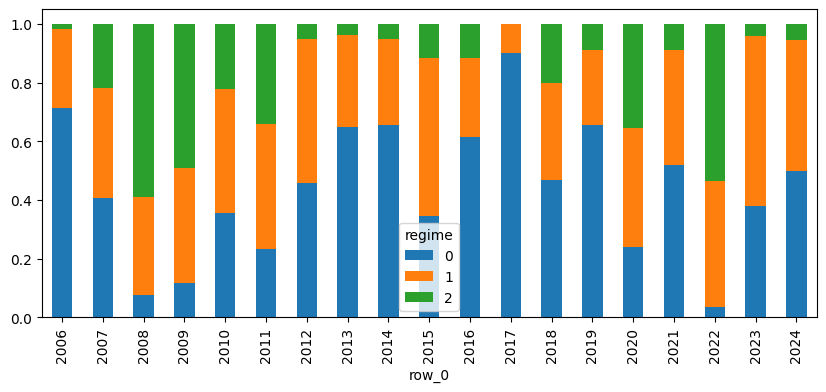

In [5]:
# regime = volatility regime of the next 5 trading days (0 calm, 1 middle, 2 crisis)
print("cutoffs (annualized vol):", cutoffs(tab.fwd_rv).round(4))
print(tab.regime.value_counts().sort_index())
pd.crosstab(tab.index.year, tab.regime, normalize="index").plot.bar(stacked=True, figsize=(10, 4))
plt.show()

The raw fwd_rv is very right-skewed (skew 3.8), but the log version is close to a bell shape (skew 0.1). So log(fwd_rv) should be used for modeling and converted back for reporting. Median forward vol rises with the regime (0.070, 0.147, 0.279).

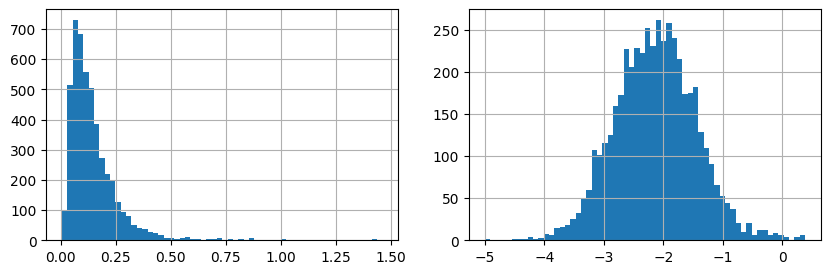

3.828842889553301 0.11948405801629709
regime
0    0.069985
1    0.147217
2    0.278972
Name: fwd_rv, dtype: float64


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
tab.fwd_rv.hist(bins=60, ax=ax[0])
np.log(tab.fwd_rv).hist(bins=60, ax=ax[1])
plt.show()
print(tab.fwd_rv.skew(), np.log(tab.fwd_rv).skew())
print(tab.groupby("regime").fwd_rv.median())

## 5. Price and volume

Close trends from about 50 to about 594, so it's a non-stationary level. Returns show volatility clustering around actual crash dates, while the largest up days are next to the largest down days (excess kurtosis 14). rv_21 peaks at about 0.93 in 2008 and 0.94 in 2020, but only about 0.35 in 2022.

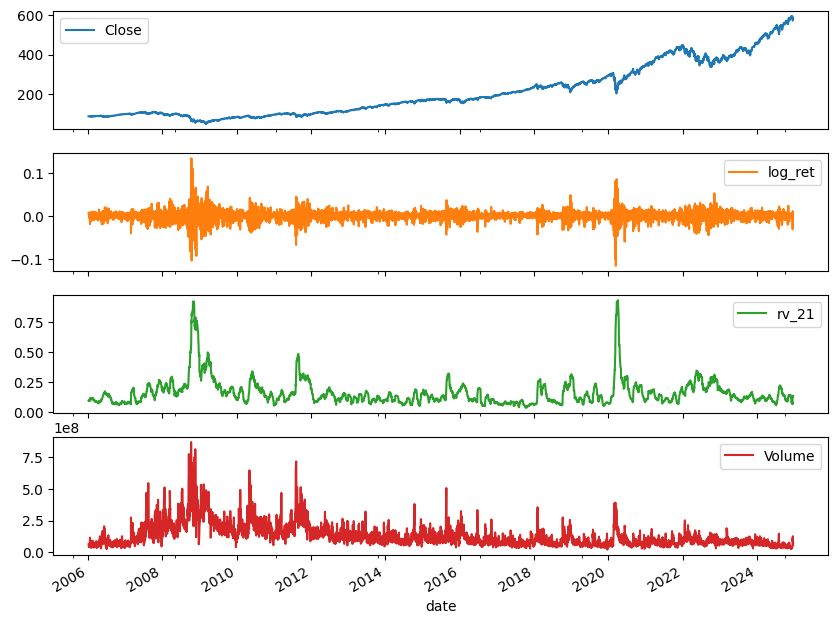

In [7]:
tab[["Close", "log_ret", "rv_21", "Volume"]].plot(subplots=True, figsize=(10, 8))
plt.show()

In [8]:
print(tab.log_ret.nsmallest(8))
print(tab.log_ret.nlargest(8))
print("excess kurtosis:", tab.log_ret.kurt())

date
2020-03-16   -0.115887
2008-10-15   -0.103638
2020-03-12   -0.100569
2008-12-01   -0.092749
2008-09-29   -0.081603
2020-03-09   -0.081313
2008-11-20   -0.077133
2008-10-09   -0.072398
Name: log_ret, dtype: float64
date
2008-10-13    0.135577
2008-10-28    0.110517
2020-03-24    0.086731
2020-03-13    0.082028
2009-03-23    0.069367
2008-11-24    0.066996
2020-04-06    0.065007
2008-11-13    0.060474
Name: log_ret, dtype: float64
excess kurtosis: 14.021292312676135


## 6. Macro features

CPI and fed funds move in steps, and the spread moves daily. All three track history correctly.

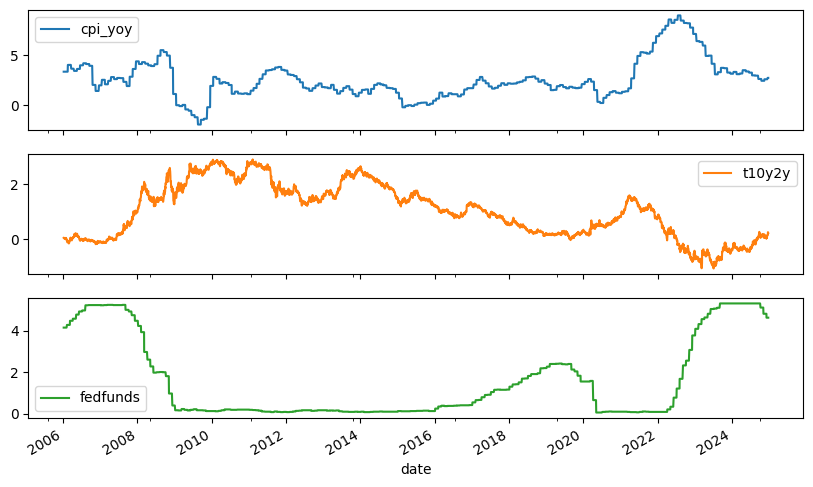

In [9]:
tab[["cpi_yoy", "t10y2y", "fedfunds"]].plot(subplots=True, figsize=(10, 6))
plt.show()

## 7. Correlations

Open/High/Low/Close are all 1.00 with each other, and Volume/log_volume are 1.00. Price level correlates -0.62 with the spread and -0.61 with volume.
`regime` correlates 0.93 with `fwd_rv`, as expected since it is a bucketed version of it. Among the inputs, `hl_range` (0.58), `rv_21` (0.57), `rv_5` (0.54) and `rel_volume` (0.38) correlate most with `fwd_rv`. log_ret vs fwd_rv is -0.13, so falling prices tend to precede higher vol.
The macro columns are only weakly correlated with the target (-0.04 to 0.12) and collinear with each other (fed funds vs spread -0.71). Because they move so slowly, they may invite memorizing periods.

In [10]:
tab.corr(method="spearman").round(2)

,Open,High,Low,Close,Volume,log_ret,rv_21,log_volume,rel_volume,hl_range,cpi_yoy,t10y2y,fedfunds,rv_5,fwd_rv,regime
Open,1.00,1.00,1.00,1.00,-0.61,0.01,-0.18,-0.61,-0.12,-0.21,0.25,-0.62,0.14,-0.16,-0.15,-0.14
High,1.00,1.00,1.00,1.00,-0.61,0.01,-0.17,-0.61,-0.12,-0.20,0.25,-0.62,0.14,-0.16,-0.15,-0.13
Low,1.00,1.00,1.00,1.00,-0.62,0.01,-0.18,-0.62,-0.13,-0.22,0.25,-0.62,0.14,-0.16,-0.15,-0.14
Close,1.00,1.00,1.00,1.00,-0.61,0.02,-0.18,-0.61,-0.12,-0.21,0.25,-0.62,0.14,-0.16,-0.15,-0.14
Volume,-0.61,-0.61,-0.62,-0.61,1.00,-0.10,0.51,1.00,0.64,0.68,-0.12,0.56,-0.23,0.55,0.46,0.43
log_ret,0.01,0.01,0.01,0.02,-0.10,1.00,0.01,-0.10,-0.15,-0.09,-0.03,0.00,-0.02,0.02,-0.13,-0.12
rv_21,-0.18,-0.17,-0.18,-0.18,0.51,0.01,1.00,0.51,0.35,0.65,0.09,0.11,-0.08,0.75,0.57,0.55
log_volume,-0.61,-0.61,-0.62,-0.61,1.00,-0.10,0.51,1.00,0.64,0.68,-0.12,0.56,-0.23,0.55,0.46,0.43
rel_volume,-0.12,-0.12,-0.13,-0.12,0.64,-0.15,0.35,0.64,1.00,0.65,0.20,-0.05,0.08,0.48,0.38,0.35
hl_range,-0.21,-0.20,-0.22,-0.21,0.68,-0.09,0.65,0.68,0.65,1.00,0.11,0.10,-0.03,0.69,0.58,0.54


The macro ranges in test are far outside train: fed funds was 0.07 to 1.16 in train but reaches 5.33 in test, CPI tops out at 3.8 in train vs 9.0 in test, and the spread is inverted (down to -1.08) in test but never below 0.51 in train.
Relative volume (volume vs its trailing 1-year mean) removes the long-term volume trend.

The regime of the last 5 days matches the regime of the next 5 days 56.8% of the time, so persistence is a real baseline but far from perfect, and direct jumps between calm and crisis do happen (109 calm to crisis, 86 crisis to calm).
For comparison, the old HMM labels had "same as tomorrow" right 97.7% of the time (computed in `notebooks/milestone1.ipynb`), which is why we replaced them.

In [11]:
cols = ["cpi_yoy", "t10y2y", "fedfunds"]
tr, te = tab.loc[split_days(tab, "train")], tab.loc[split_days(tab, "test")]
print(pd.concat({"train": tr[cols].agg(["min", "max"]), "test": te[cols].agg(["min", "max"])}))

print("Spearman with fwd_rv: rel_volume", round(tab.rel_volume.corr(tab.fwd_rv, method="spearman"), 2),
      "| log_volume", round(tab.log_volume.corr(tab.fwd_rv, method="spearman"), 2))

# persistence: regime of the last 5 days (trailing rv_5) vs regime of the next 5
past = pd.Series(to_regime(tab.rv_5, cutoffs(tab.fwd_rv)), index=tab.index)
print("last 5 days' regime = next 5 days' regime:", round((past == tab.regime).mean(), 3))
print(pd.crosstab(past.rename("last 5 days"), tab.regime.rename("next 5 days")))

            cpi_yoy  t10y2y  fedfunds
train min -1.958761    0.51      0.07
      max  3.812622    2.91      1.16
test  min  0.198201   -1.08      0.05
      max  8.979361    1.59      5.33


Spearman with fwd_rv: rel_volume 0.38 | log_volume 0.46
last 5 days' regime = next 5 days' regime: 0.568
next 5 days     0    1    2
last 5 days                
0            1363  622  109
1             642  839  291
2              86  313  508


## 8. Train, val, test periods

Each class appears in each period, with crisis at 13%, 15% and 26% and calm at 50%, 56% and 29%. The test period is much more volatile than train, so the class mix differs a lot between periods and scores should be looked at per class.

In [12]:
split = pd.concat({s: tab.loc[split_days(tab, s), "regime"] for s in ["train", "val", "test"]})
name = pd.Categorical(split.index.get_level_values(0), ["train", "val", "test"])
print(pd.crosstab(name, split, rownames=["split"]))
print(pd.crosstab(name, split, rownames=["split"], normalize="index").round(3))

regime     0    1    2
split                 
train   1086  808  284
val      281  145   72
test     292  453  256
regime      0      1      2
split                      
train   0.499  0.371  0.130
val     0.564  0.291  0.145
test    0.292  0.453  0.256


## 9. News files

In [13]:
print(cnt.shape, cnt.index.min(), cnt.index.max())
print("Duplicates cnt:", cnt.index.duplicated().sum(), "| NaNs:", cnt.isna().sum())
if emb is not None:
    print(emb.shape, emb.index.min(), emb.index.max())
    print("Duplicates emb:", emb.index.duplicated().sum(), "| NaNs:", emb.isna().sum().sum())

(3645,) 2009-04-29 00:00:00 2024-01-09 00:00:00
Duplicates cnt: 0 | NaNs: 0
(3645, 771) 2009-04-29 00:00:00 2024-01-09 00:00:00
Duplicates emb: 0 | NaNs: 0


### 9a. news_count

News exists from 2009-04-29 to 2024-01-09.

count    3645.000000
mean       65.097394
std        35.700441
min         1.000000
25%        50.000000
50%        50.000000
75%        50.000000
max       200.000000
Name: news_count, dtype: float64


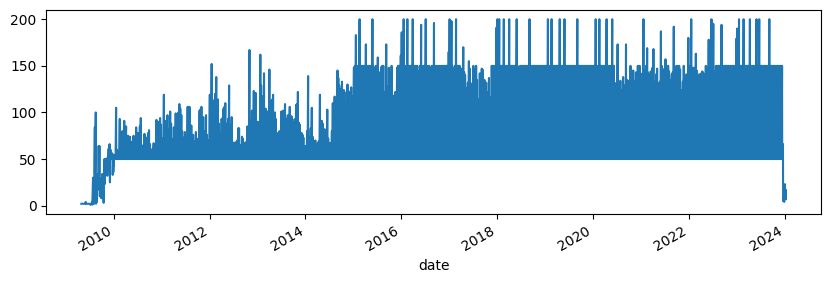

In [14]:
print(cnt.describe())
cnt.plot(figsize=(10, 3))
plt.show()

Mean daily article count is the same across regimes (66, 64, 65), and count has no correlation with forward vol (Spearman -0.01).

In [15]:
has_news = tab.index.isin(cnt.index)
n = cnt.reindex(tab.index)
print(n[has_news].groupby(tab.regime[has_news]).mean())
print("Spearman:", n[has_news].corr(tab.fwd_rv[has_news], method="spearman"))

regime
0    66.025764
1    64.092020
2    64.839316
Name: news_count, dtype: float64
Spearman: -0.012406853676902557


### 9b. news_emb

In [16]:
if emb is not None:
    print("NaNs:", emb.isna().sum().sum(), "| all-zero rows:", (emb.abs().sum(axis=1) == 0).sum())
    print(emb.std().describe())

NaNs: 0 | all-zero rows: 0
count    771.000000
mean       0.136512
std        0.045628
min        0.062129
25%        0.103554
50%        0.126569
75%        0.160944
max        0.359008
dtype: float64


In [17]:
if emb is not None:
    norms = pd.Series(np.linalg.norm(emb.values, axis=1), index=emb.index)
    print(norms.describe())
    print("Spearman(norm, article count):", norms.corr(cnt.reindex(emb.index), method="spearman"))

count    3645.000000
mean       10.418667
std         0.847773
min         8.736948
25%         9.873323
50%        10.282724
75%        10.821717
max        17.153891
dtype: float64
Spearman(norm, article count): 0.1389566061126861


In [18]:
if emb is not None:
    X = emb.values
    rng = np.random.default_rng(0)
    i, j = rng.integers(0, len(X), 2000), rng.integers(0, len(X), 2000)
    cos = (X[i] * X[j]).sum(1) / (np.linalg.norm(X[i], axis=1) * np.linalg.norm(X[j], axis=1))
    print("mean cosine similarity between random days:", cos.mean())

mean cosine similarity between random days: 0.86094826


## 10. Summary


- The main table has 4,773 trading days (2006-01-06 to 2024-12-23) and 16 columns, with no duplicate dates, no calendar gaps and no missing values. 2005 is used up by the 1-year rolling volume feature.
- `regime` is the regime of the next 5 trading days: 44% calm, 37% middle and 19% crisis over the full sample, and median forward volatility rises with the regime (0.070, 0.147, 0.279).
- The last 5 days' regime matches the next 5 days' regime 56.8% of the time, so persistence is a fair but beatable baseline. The old HMM labels were 97.7% persistent, which is why they were dropped.
- `fwd_rv` is right-skewed and close to symmetric in logs, so the regression target should be log volatility.
- Open, High, Low and Close trend from about 50 to about 594 and are perfectly correlated with each other, so they are redundant.
- `hl_range` (0.58) and `rv_21` (0.57) are the inputs most correlated with `fwd_rv`.
- The three macro features change in steps and are only weakly correlated with the target. Their test-period ranges are far outside the training ranges (fed funds up to 5.33 vs a train max of 1.16).
- News exists from 2009-04-29 to 2024-01-09.
- `news_count` has the median of 50, a floor at 50 and ceilings near 150 and 200, which looks like a sampling cap.
- Every class appears in every period, but the test period has twice the crisis share of train, mostly from 2022 and COVID.


### Cleaning decisions
- Open, High, Low, Close levels and `Volume` are redundant
- Volume trend - use relative volume
- Skewed volatility target - model log `fwd_rv`
- Macro levels shift out of the training range - check whether they help on validation
- News missing before 2009 and in 2024
- HMM labels 97.7% persistent - replaced by forward-vol regimes